In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.feature_selection import SelectKBest, mutual_info_classif

from sklearn.model_selection import train_test_split

In [2]:
target = "JobSatLevel"
target_order = ["Low", "Average", "High"]
target_mapping = {level: i for i, level in enumerate(target_order)}

df = pd.read_csv("train_data.csv")
df = df.drop_duplicates()


df.dropna(subset=[target], inplace=True)

unexpected_levels = sorted(set(df[target].dropna().unique()) - set(target_order))
if unexpected_levels:
    print("Unexpected target levels found and removed:", unexpected_levels)
    df = df[df[target].isin(target_order)].copy()

df[target] = pd.Categorical(df[target], categories=target_order, ordered=True)

print(df.shape)
print(df[target].value_counts().reindex(target_order))
print((df[target].value_counts(normalize=True).reindex(target_order) * 100).round(2))


C:\Users\hossa\AppData\Local\Temp\ipykernel_19596\1304858184.py:5: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("train_data.csv")


(23961, 156)
JobSatLevel
Low         6803
Average    11296
High        5862
Name: count, dtype: int64
JobSatLevel
Low        28.39
Average    47.14
High       24.46
Name: proportion, dtype: float64


In [3]:
meaning = pd.read_csv("survey_results_schema.csv")
link = dict()

for i in df.columns:
    for j in meaning["qname"]:
        if i == j:
            link[i] = meaning[meaning["qname"] == j]["question"].values[0]
link


{'MainBranch': 'Are you someone who writes code? Please select one of the following options that best describes you today.',
 'Age': 'What is your age?',
 'EdLevel': 'Which of the following best describes the highest level of formal education that you’ve completed? ',
 'Employment': 'Which of the following best describes your current employment status?<br>',
 'EmploymentAddl': 'Which of the following <strong>additional</strong> activities are you currently engaged in?',
 'WorkExp': "How many years of professional work experience do you have? Please round to the nearest whole number, excluding any decimal points.  If your answer is '0', please leave blank.",
 'LearnCodeChoose': 'Did you begin learning to code or learn a new coding skill/programming language in the last year?',
 'LearnCode': 'How did you learn to code in the past year? Select all that apply.',
 'LearnCodeAI': 'Did you spend time in the last year learning AI programming or AI-enabled tooling on your own or at work?',
 'AI

In [4]:

Hossamcolumns = []
for i in df.columns:
    if i.startswith("Tool") or i.startswith("DevEnvs") or i.startswith("Webframe") or i.startswith("CommPlat") or i.startswith("OpSys"):
        Hossamcolumns.append(i)

extra_cols = ["PurchaseInfluence", "EmploymentAddl", "Industry", "AgentUsesGeneral"]
existing_extra_cols = [col for col in extra_cols if col in df.columns]


Hossamcolumns.extend(existing_extra_cols)

print(len(Hossamcolumns))
print(Hossamcolumns)



23
['ToolCountWork', 'ToolCountPersonal', 'WebframeChoice', 'WebframeHaveWorkedWith', 'WebframeWantToWorkWith', 'WebframeAdmired', 'WebframeHaveEntry', 'WebframeWantEntry', 'DevEnvsChoice', 'DevEnvsHaveWorkedWith', 'DevEnvsWantToWorkWith', 'DevEnvsAdmired', 'OpSysPersonal use', 'OpSysProfessional use', 'CommPlatformHaveWorkedWith', 'CommPlatformWantToWorkWith', 'CommPlatformAdmired', 'CommPlatformHaveEntr', 'CommPlatformWantEntr', 'PurchaseInfluence', 'EmploymentAddl', 'Industry', 'AgentUsesGeneral']


In [5]:
if target not in Hossamcolumns:
    Hossamcolumns.append(target)

myDf = df[Hossamcolumns].copy()

c = 0
for i in Hossamcolumns:
    if i in link:
        print(f"{i}: {link[i]}")
        c += 1
print(f"Number of matching columns: {c}")


ToolCountWork: For your <b>primary work role</b> (student, developer, or technologist) over the past year:
<br><br>Excluding general operating systems (like Windows or macOS) and web browsers, <b>how many distinct software applications or platforms</b> did you regularly use to create, analyze, manage, or share information in order to do your job?

Please enter a whole number below with no punctuation, or leave blank.
ToolCountPersonal: <b></b>For your <b>side projects or other personal work</b> over the past year (focus on the project you spent the most time on if applicable):
<br><br>Excluding general operating systems and web browsers, how many <b>distinct software applications or platforms</b> did you regularly use to do your job? Please enter a whole number below with no punctuation, or leave blank.
WebframeChoice: Did you work with web frameworks and web technologies in the last year or do you plan to in the year to come?  Here, we are referring to technology that helps website an

In [6]:
manyNulls = []
for i in Hossamcolumns:
    if i == target:
        continue
    nulls = myDf[i].isnull().sum()
    if nulls / len(myDf) > 0.7:
        manyNulls.append(i)

print(len(manyNulls))
print(manyNulls)

for i in manyNulls:
    Hossamcolumns.remove(i)

print(len(Hossamcolumns))


5
['WebframeHaveEntry', 'WebframeWantEntry', 'CommPlatformHaveEntr', 'CommPlatformWantEntr', 'AgentUsesGeneral']
19


In [7]:
myDf.drop(columns=manyNulls, inplace=True)


In [8]:
def is_multi_value(df, col):
    return df[col].dropna().astype(str).str.contains(";").any()


def explode_col(df, col, target_col=target):
    exploded = df[[col, target_col]].copy()
    exploded[col] = exploded[col].astype(str).str.split(";")
    exploded = exploded.explode(col).reset_index(drop=True)
    exploded[col] = exploded[col].str.strip()
    return exploded


In [9]:

category = []
for i in Hossamcolumns:
    if i != target and myDf[i].dtype == "object":
        category.append(i)
print(len(category))
print(category)

numeric = []
for i in myDf.columns:
    if i != target and myDf[i].dtype != "object":
        numeric.append(i)
print(len(numeric))
print(numeric)

multi_value_cols = []
single_value_cols = []

for col in category:
    if is_multi_value(myDf, col):
        multi_value_cols.append(col)
    else:
        single_value_cols.append(col)

print("Multi-value:", multi_value_cols)
print("Single-value:", single_value_cols)


16
['WebframeChoice', 'WebframeHaveWorkedWith', 'WebframeWantToWorkWith', 'WebframeAdmired', 'DevEnvsChoice', 'DevEnvsHaveWorkedWith', 'DevEnvsWantToWorkWith', 'DevEnvsAdmired', 'OpSysPersonal use', 'OpSysProfessional use', 'CommPlatformHaveWorkedWith', 'CommPlatformWantToWorkWith', 'CommPlatformAdmired', 'PurchaseInfluence', 'EmploymentAddl', 'Industry']
2
['ToolCountWork', 'ToolCountPersonal']
Multi-value: ['WebframeHaveWorkedWith', 'WebframeWantToWorkWith', 'WebframeAdmired', 'DevEnvsHaveWorkedWith', 'DevEnvsWantToWorkWith', 'DevEnvsAdmired', 'OpSysPersonal use', 'OpSysProfessional use', 'CommPlatformHaveWorkedWith', 'CommPlatformWantToWorkWith', 'CommPlatformAdmired', 'EmploymentAddl']
Single-value: ['WebframeChoice', 'DevEnvsChoice', 'PurchaseInfluence', 'Industry']


In [10]:
myDf_train, myDf_test = train_test_split(
    myDf,
    test_size=0.2,
    random_state=42,
    stratify=myDf[target]
)

print("Train shape:", myDf_train.shape)
print("Test shape:", myDf_test.shape)
print("Train target distribution:")
print(myDf_train[target].value_counts(normalize=True).reindex(target_order).round(3))
print("Test target distribution:")
print(myDf_test[target].value_counts(normalize=True).reindex(target_order).round(3))


Train shape: (19168, 19)
Test shape: (4793, 19)
Train target distribution:
JobSatLevel
Low        0.284
Average    0.471
High       0.245
Name: proportion, dtype: float64
Test target distribution:
JobSatLevel
Low        0.284
Average    0.471
High       0.245
Name: proportion, dtype: float64


In [11]:
for col in single_value_cols:
    if col in myDf_train.columns:
        mode_value = myDf_train[col].mode(dropna=True)
        fill_value = mode_value.iloc[0] if not mode_value.empty else "Unknown"
        myDf_train[col] = myDf_train[col].fillna(fill_value)
        myDf_test[col] = myDf_test[col].fillna(fill_value)

for col in numeric:
    if col in myDf_train.columns:
        median_value = myDf_train[col].median()
        fill_value = median_value if pd.notna(median_value) else 0
        myDf_train[col] = myDf_train[col].fillna(fill_value)
        myDf_test[col] = myDf_test[col].fillna(fill_value)

for col in multi_value_cols:
    if col in myDf_train.columns:
        myDf_train[col] = myDf_train[col].fillna("Unknown")
        myDf_test[col] = myDf_test[col].fillna("Unknown")

myDf = myDf_train.copy()
print("Train nulls remaining:", myDf_train.isnull().sum().sum())
print("Test nulls remaining:", myDf_test.isnull().sum().sum())

Train nulls remaining: 0
Test nulls remaining: 0


In [12]:
for i in category:
    print(f"{i}: {myDf[i].nunique()}")


WebframeChoice: 2
WebframeHaveWorkedWith: 4918
WebframeWantToWorkWith: 3700
WebframeAdmired: 2143
DevEnvsChoice: 2
DevEnvsHaveWorkedWith: 5031
DevEnvsWantToWorkWith: 3473
DevEnvsAdmired: 2620
OpSysPersonal use: 1309
OpSysProfessional use: 914


CommPlatformHaveWorkedWith: 4189
CommPlatformWantToWorkWith: 3236
CommPlatformAdmired: 2905
PurchaseInfluence: 5
EmploymentAddl: 119
Industry: 15


In [13]:
myDf[target].value_counts().reindex(target_order)


JobSatLevel
Low        5442
Average    9037
High       4689
Name: count, dtype: int64

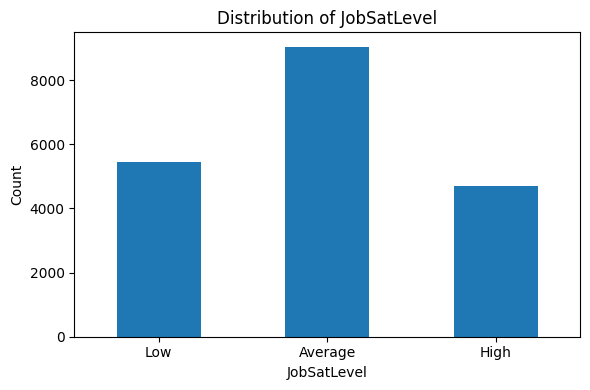

In [14]:
class_counts = myDf[target].value_counts().reindex(target_order)

plt.figure(figsize=(6, 4))
class_counts.plot(kind="bar")
plt.title("Distribution of JobSatLevel")
plt.xlabel("JobSatLevel")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [15]:
drop_cols = [col for col in ["ToolCountWork", "ToolCountPersonal"] if col in myDf.columns]
myDf.drop(columns=drop_cols, inplace=True)
print("Dropped columns:", drop_cols)


Dropped columns: ['ToolCountWork', 'ToolCountPersonal']


In [16]:
print(len(myDf.columns))
myDf.head(10)


17


,WebframeChoice,WebframeHaveWorkedWith,WebframeWantToWorkWith,WebframeAdmired,DevEnvsChoice,DevEnvsHaveWorkedWith,DevEnvsWantToWorkWith,DevEnvsAdmired,OpSysPersonal use,OpSysProfessional use,CommPlatformHaveWorkedWith,CommPlatformWantToWorkWith,CommPlatformAdmired,PurchaseInfluence,EmploymentAddl,Industry,JobSatLevel
43167,Yes,Unknown,Unknown,Unknown,Yes,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,No,None of the above,Software Development,Low
27412,Yes,Vue.js,Unknown,Unknown,No,Unknown,Unknown,Unknown,Windows;Android;Windows Subsystem for Linux (W...,Windows;Linux (non-WSL),Stack Overflow;Stack Exchange;Discord;Reddit;H...,Stack Overflow;Stack Exchange;YouTube;Twitch,Stack Overflow;Stack Exchange;YouTube;Twitch,"Yes, I endorsed a tool that was open-source an...",None of the above,Software Development,Average
17585,Yes,Unknown,Unknown,Unknown,Yes,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,No,Unknown,Software Development,Average
3739,Yes,jQuery;WordPress,Angular;AngularJS;Django;FastAPI;jQuery;Larave...,jQuery;WordPress,Yes,Android Studio;Nano;Notepad++;Vim,Android Studio;Eclipse;Nano;Notepad++;PhpStorm...,Android Studio;Nano;Notepad++;Vim,Ubuntu;Android;Windows Subsystem for Linux (WS...,Windows;MacOS;Ubuntu;Android;Windows Subsystem...,Stack Overflow;Stack Exchange;Discord;GitHub (...,Stack Overflow;Stack Exchange;GitHub (public p...,Stack Overflow;Stack Exchange;GitHub (public p...,"Yes, I endorsed a tool that was open-source an...","Caring for dependents (children, elderly, etc....",Computer Systems Design and Services,Low
8068,Yes,Unknown,Unknown,Unknown,Yes,Jupyter Notebook/JupyterLab;Visual Studio;Visu...,VSCodium,VSCodium,Pop!_OS,Windows;Ubuntu,Stack Overflow;Stack Exchange;GitHub (public p...,Stack Overflow;Stack Exchange;GitHub (public p...,Stack Overflow;Stack Exchange;GitHub (public p...,"Yes, I influenced the purchase of a substantia...",None of the above,Fintech,Low
5884,No,Unknown,Unknown,Unknown,Yes,Visual Studio;Visual Studio Code,Visual Studio Code,Visual Studio Code,Windows;MacOS;Ubuntu;Android;Windows Subsystem...,Ubuntu;Debian;Linux (non-WSL),Stack Overflow;Stack Exchange;GitHub (public p...,Stack Overflow;Stack Exchange;GitHub (public p...,Stack Overflow;Stack Exchange;GitHub (public p...,No,Unknown,Software Development,High
36536,No,Unknown,Unknown,Unknown,Yes,Aider;Cline and/or Roo;Cursor;Visual Studio Co...,Aider;Claude Code;Cline and/or Roo;Cursor;Visu...,Aider;Cline and/or Roo;Cursor;Visual Studio Co...,MacOS;Android,MacOS,"Reddit;Hacker News;GitHub (public projects, no...","Reddit;Hacker News;GitHub (public projects, no...","Reddit;Hacker News;GitHub (public projects, no...","Yes, I endorsed a tool that was open-source an...",None of the above,Software Development,Average
31667,Yes,Angular;Express;Flask;Next.js;Node.js;React;Axum,Angular;Axum,Angular;Axum,Yes,Android Studio;Visual Studio Code;Xcode;Zed,Android Studio;Xcode;Zed,Android Studio;Xcode;Zed,MacOS;iOS;Debian;Linux (non-WSL);iPadOS;Fedora,MacOS;Android;Debian;Linux (non-WSL);Fedora,Stack Overflow;Stack Exchange;Discord;Reddit;D...,Stack Overflow;Stack Exchange;Discord;Reddit;D...,Stack Overflow;Stack Exchange;Discord;Reddit;D...,"Yes, I influenced the purchase of a substantia...","Caring for dependents (children, elderly, etc....",Software Development,High
10692,Yes,Angular;ASP.NET;ASP.NET Core;Blazor;React,ASP.NET;ASP.NET Core;React,ASP.NET;ASP.NET Core;React,Yes,Visual Studio;Visual Studio Code,Visual Studio Code,Visual Studio Code,Windows,Windows;Ubuntu;Windows Subsystem for Linux (WSL),"GitHub (public projects, not private repos);Li...","GitHub (public projects, not private repos);Li...","GitHub (public projects, not private repos);Li...",No,None of the above,Healthcare,Average
13861,Yes,Angular;ASP.NET;ASP.NET Core;Blazor;jQuery;Wor...,Unknown,Unknown,No,Unknown,Unknown,Unknown,Windows;Ubuntu;Linux (non-WSL),Windows;Windows Subsystem for Linux (WSL),Stack Overflow;Stack Exchange;Reddit,Unknown,Unk

In [17]:
single_value_cols


['WebframeChoice', 'DevEnvsChoice', 'PurchaseInfluence', 'Industry']

In [18]:
multi_value_cols


['WebframeHaveWorkedWith',
 'WebframeWantToWorkWith',
 'WebframeAdmired',
 'DevEnvsHaveWorkedWith',
 'DevEnvsWantToWorkWith',
 'DevEnvsAdmired',
 'OpSysPersonal use',
 'OpSysProfessional use',
 'CommPlatformHaveWorkedWith',
 'CommPlatformWantToWorkWith',
 'CommPlatformAdmired',
 'EmploymentAddl']

In [19]:
myDf.head(5)


,WebframeChoice,WebframeHaveWorkedWith,WebframeWantToWorkWith,WebframeAdmired,DevEnvsChoice,DevEnvsHaveWorkedWith,DevEnvsWantToWorkWith,DevEnvsAdmired,OpSysPersonal use,OpSysProfessional use,CommPlatformHaveWorkedWith,CommPlatformWantToWorkWith,CommPlatformAdmired,PurchaseInfluence,EmploymentAddl,Industry,JobSatLevel
43167,Yes,Unknown,Unknown,Unknown,Yes,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,No,None of the above,Software Development,Low
27412,Yes,Vue.js,Unknown,Unknown,No,Unknown,Unknown,Unknown,Windows;Android;Windows Subsystem for Linux (W...,Windows;Linux (non-WSL),Stack Overflow;Stack Exchange;Discord;Reddit;H...,Stack Overflow;Stack Exchange;YouTube;Twitch,Stack Overflow;Stack Exchange;YouTube;Twitch,"Yes, I endorsed a tool that was open-source an...",None of the above,Software Development,Average
17585,Yes,Unknown,Unknown,Unknown,Yes,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,No,Unknown,Software Development,Average
3739,Yes,jQuery;WordPress,Angular;AngularJS;Django;FastAPI;jQuery;Larave...,jQuery;WordPress,Yes,Android Studio;Nano;Notepad++;Vim,Android Studio;Eclipse;Nano;Notepad++;PhpStorm...,Android Studio;Nano;Notepad++;Vim,Ubuntu;Android;Windows Subsystem for Linux (WS...,Windows;MacOS;Ubuntu;Android;Windows Subsystem...,Stack Overflow;Stack Exchange;Discord;GitHub (...,Stack Overflow;Stack Exchange;GitHub (public p...,Stack Overflow;Stack Exchange;GitHub (public p...,"Yes, I endorsed a tool that was open-source an...","Caring for dependents (children, elderly, etc....",Computer Systems Design and Services,Low
8068,Yes,Unknown,Unknown,Unknown,Yes,Jupyter Notebook/JupyterLab;Visual Studio;Visu...,VSCodium,VSCodium,Pop!_OS,Windows;Ubuntu,Stack Overflow;Stack Exchange;GitHub (public p...,Stack Overflow;Stack Exchange;GitHub (public p...,Stack Overflow;Stack Exchange;GitHub (public p...,"Yes, I influenced the purchase of a substantia...",None of the above,Fintech,Low


In [20]:
def multi_hot_encode_train_test(train_df, test_df, cols):
    train_df = train_df.copy()
    test_df = test_df.copy()

    for col in cols:
        train_lists = train_df[col].fillna("").apply(
            lambda x: [item.strip() for item in str(x).split(";") if item.strip()]
        )
        test_lists = test_df[col].fillna("").apply(
            lambda x: [item.strip() for item in str(x).split(";") if item.strip()]
        )

        mlb = MultiLabelBinarizer()
        train_encoded = mlb.fit_transform(train_lists)
        test_encoded = mlb.transform(test_lists)

        encoded_cols = [f"{col}_{c}" for c in mlb.classes_]

        train_encoded_df = pd.DataFrame(train_encoded, columns=encoded_cols, index=train_df.index)
        test_encoded_df = pd.DataFrame(test_encoded, columns=encoded_cols, index=test_df.index)

        train_df = pd.concat([train_df.drop(columns=[col]), train_encoded_df], axis=1)
        test_df = pd.concat([test_df.drop(columns=[col]), test_encoded_df], axis=1)

    return train_df, test_df

myDf_train, myDf_test = multi_hot_encode_train_test(myDf_train, myDf_test, multi_value_cols)
myDf = myDf_train.copy()
print("Train shape:", myDf_train.shape)
print("Test shape:", myDf_test.shape)

Train shape: (19168, 277)
Test shape: (4793, 277)


In [21]:
myDf.head(10)


,ToolCountWork,ToolCountPersonal,WebframeChoice,DevEnvsChoice,PurchaseInfluence,Industry,JobSatLevel,WebframeHaveWorkedWith_ASP.NET,WebframeHaveWorkedWith_ASP.NET Core,WebframeHaveWorkedWith_Angular,...,EmploymentAddl_Attending school (full-time),EmploymentAddl_Attending school (part-time),"EmploymentAddl_Caring for dependents (children, elderly, etc.)",EmploymentAddl_Engaged in paid work (10-19 hours per week),EmploymentAddl_Engaged in paid work (20-29 hours per week),EmploymentAddl_Engaged in paid work (less than 10 hours per week),EmploymentAddl_None of the above,EmploymentAddl_Transitioning to retirement (gradually reducing work hours),EmploymentAddl_Unknown,EmploymentAddl_Volunteering (regularly)
43167,5.0,2.0,Yes,Yes,No,Software Development,Low,0,0,0,...,0,0,0,0,0,0,1,0,0,0
27412,8.0,4.0,Yes,No,"Yes, I endorsed a tool that was open-source an...",Software Development,Average,0,0,0,...,0,0,0,0,0,0,1,0,0,0
17585,2.0,5.0,Yes,Yes,No,Software Development,Average,0,0,0,...,0,0,0,0,0,0,0,0,1,0
3739,10.0,10.0,Yes,Yes,"Yes, I endorsed a tool that was open-source an...",Computer Systems Design and Services,Low,0,0,0,...,0,0,1,1,0,0,0,0,0,0
8068,5.0,6.0,Yes,Yes,"Yes, I influenced the purchase of a substantia...",Fintech,Low,0,0,0,...,0,0,0,0,0,0,1,0,0,0
5884,6.0,5.0,No,Yes,No,Software Development,High,0,0,0,...,0,0,0,0,0,0,0,0,1,0
36536,6.0,5.0,No,Yes,"Yes, I endorsed a tool that was open-source an...",Software Development,Average,0,0,0,...,0,0,0,0,0,0,1,0,0,0
31667,6.0,6.0,Yes,Yes,"Yes, I influenced the purchase of a substantia...",Software Development,High,0,0,1,...,0,0,1,0,1,0,0,0,0,0
10692,5.0,2.0,Yes,Yes,No,Healthcare,Average,1,1,1,...,0,0,0,0,0,0,1,0,0,0
13861,9.0,6.0,Yes,No,No,Insurance,Average,1,1,1,...,0,0,1,0,0,0,0,0,0,0


In [22]:
object_cols = []
for i in myDf.columns:
    if i != target and myDf[i].dtype == "object":
        object_cols.append(i)
object_cols


['WebframeChoice', 'DevEnvsChoice', 'PurchaseInfluence', 'Industry']

In [23]:
single_value_cols


['WebframeChoice', 'DevEnvsChoice', 'PurchaseInfluence', 'Industry']

In [24]:
for i in single_value_cols:
    if i in myDf.columns:
        print(f"{i}: {myDf[i].nunique()}")


WebframeChoice: 2
DevEnvsChoice: 2
PurchaseInfluence: 5
Industry: 15


In [25]:
myDf_train = pd.get_dummies(
    myDf_train,
    columns=single_value_cols,
    drop_first=True,
    dtype=int
)

myDf_test = pd.get_dummies(
    myDf_test,
    columns=single_value_cols,
    drop_first=True,
    dtype=int
)

myDf_test = myDf_test.reindex(columns=myDf_train.columns, fill_value=0)
myDf = myDf_train.copy()

print("Train shape:", myDf_train.shape)
print("Test shape:", myDf_test.shape)

Train shape: (19168, 293)
Test shape: (4793, 293)


In [26]:
feature_dtypes = myDf.drop(columns=[target]).dtypes.value_counts()
feature_dtypes


int64      290
float64      2
Name: count, dtype: int64

In [27]:
print("Target encoding used for classification:")
print(target_mapping)


Target encoding used for classification:
{'Low': 0, 'Average': 1, 'High': 2}


In [28]:
X_train = myDf_train.drop(columns=[target]).copy()
X_test = myDf_test.drop(columns=[target]).copy()

X_train = X_train.apply(pd.to_numeric, errors="coerce").fillna(0)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
X_test = X_test.apply(pd.to_numeric, errors="coerce").fillna(0)

y_train = myDf_train[target].astype(str)
y_test = myDf_test[target].astype(str)

y_train_encoded = y_train.map(target_mapping).astype(int)
y_test_encoded = y_test.map(target_mapping).astype(int)

min_count = 20

binary_cols = [
    col for col in X_train.columns
    if set(X_train[col].dropna().unique()).issubset({0, 1})
]

rare_cols = [col for col in binary_cols if X_train[col].sum() < min_count]
X_train_filtered = X_train.drop(columns=rare_cols)
X_test_filtered = X_test.drop(columns=rare_cols)

k = min(30, X_train_filtered.shape[1])
selector = SelectKBest(score_func=mutual_info_classif, k=k)
selector.fit(X_train_filtered, y_train_encoded)

selected_features = X_train_filtered.columns[selector.get_support()]
selected_scores = selector.scores_[selector.get_support()]

selected_scores_df = pd.DataFrame({
    "feature": selected_features,
    "mutual_info_score": selected_scores
}).sort_values("mutual_info_score", ascending=False).reset_index(drop=True)

# Keep the old variable names for the following cells
X = X_train
X_filtered = X_train_filtered
y = y_train
y_encoded = y_train_encoded

print("Removed rare columns:", len(rare_cols))
print("Selected features:", len(selected_features))
print("X_train_filtered:", X_train_filtered.shape)
print("X_test_filtered:", X_test_filtered.shape)
selected_scores_df

Removed rare columns: 0
Selected features: 30
X_train_filtered: (19168, 292)
X_test_filtered: (4793, 292)


,feature,mutual_info_score
0,WebframeHaveWorkedWith_Node.js,0.013393
1,DevEnvsHaveWorkedWith_Cursor,0.010415
2,Industry_Software Development,0.009596
3,DevEnvsAdmired_Unknown,0.009151
4,Industry_Fintech,0.008828
5,DevEnvsHaveWorkedWith_Unknown,0.007993
6,DevEnvsWantToWorkWith_Notepad++,0.007211
7,"PurchaseInfluence_Yes, I endorsed a tool that ...",0.007130
8,CommPlatformHaveWorkedWith_Discord,0.006868
9,DevEnvsAdmired_IntelliJ IDEA,0.006507


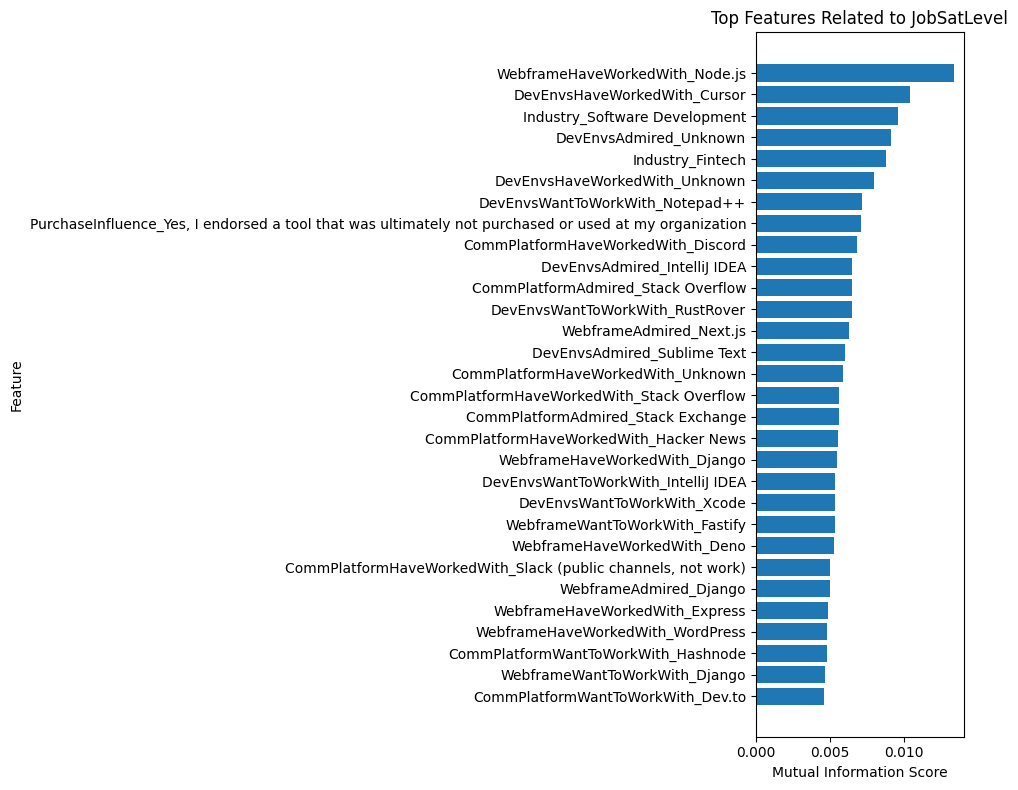

In [29]:
plot_df = selected_scores_df.sort_values("mutual_info_score", ascending=True)

plt.figure(figsize=(10, 8))
plt.barh(plot_df["feature"], plot_df["mutual_info_score"])
plt.title("Top Features Related to JobSatLevel")
plt.xlabel("Mutual Information Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [30]:
top_n = 10

for feature in selected_scores_df["feature"].head(top_n):
    print()
    print("=" * 100)
    print(feature)
    print("Counts:")
    display(pd.crosstab(X_filtered[feature], y, margins=True))
    print("Percentages by feature value:")
    display((pd.crosstab(X_filtered[feature], y, normalize="index") * 100).round(2))



WebframeHaveWorkedWith_Node.js
Counts:


JobSatLevel,Average,High,Low,All
WebframeHaveWorkedWith_Node.js,,,,
0,5871,3124,3562,12557
1,3166,1565,1880,6611
All,9037,4689,5442,19168


Percentages by feature value:


JobSatLevel,Average,High,Low
WebframeHaveWorkedWith_Node.js,,,
0,46.75,24.88,28.37
1,47.89,23.67,28.44



DevEnvsHaveWorkedWith_Cursor
Counts:


JobSatLevel,Average,High,Low,All
DevEnvsHaveWorkedWith_Cursor,,,,
0,7726,4002,4680,16408
1,1311,687,762,2760
All,9037,4689,5442,19168


... (30 outputs left out)


DevEnvsAdmired_IntelliJ IDEA
Counts:


JobSatLevel,Average,High,Low,All
DevEnvsAdmired_IntelliJ IDEA,,,,
0,7857,4151,4740,16748
1,1180,538,702,2420
All,9037,4689,5442,19168


Percentages by feature value:


JobSatLevel,Average,High,Low
DevEnvsAdmired_IntelliJ IDEA,,,
0,46.91,24.79,28.30
1,48.76,22.23,29.01


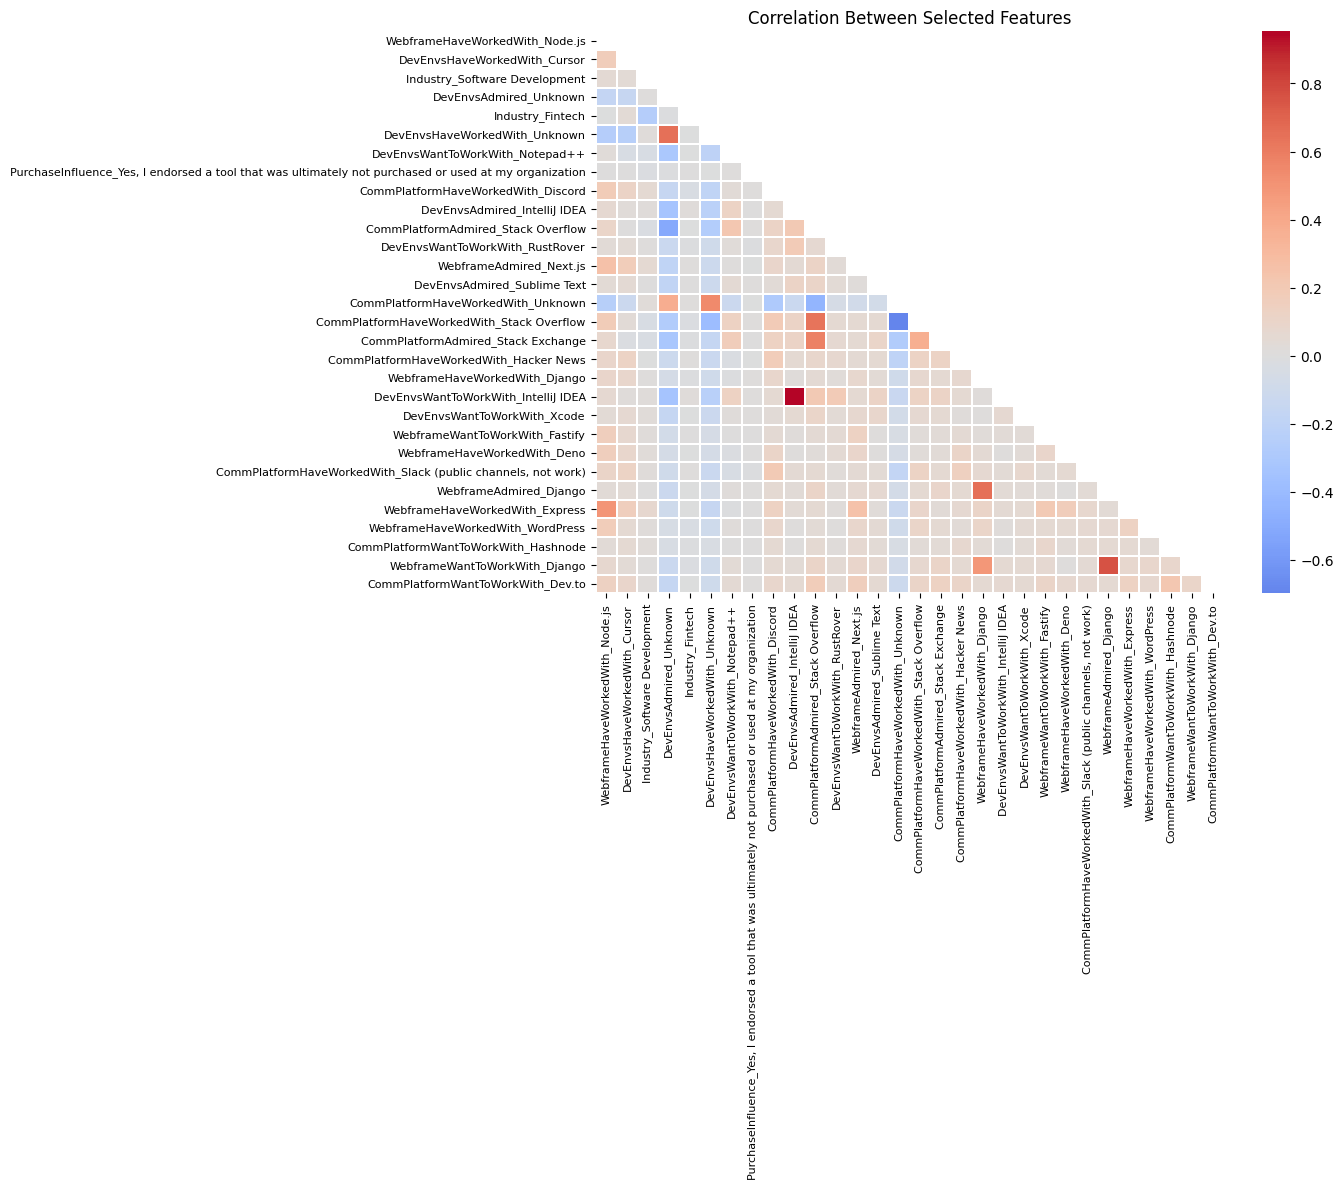

In [31]:
selected_feature_names = selected_scores_df["feature"].tolist()
selected_corr_matrix = X_filtered[selected_feature_names].corr(numeric_only=True)

mask = np.triu(np.ones_like(selected_corr_matrix, dtype=bool))

plt.figure(figsize=(14, 12))
sns.heatmap(
    selected_corr_matrix,
    mask=mask,
    cmap="coolwarm",
    center=0,
    linewidths=0.3,
    annot=False
)

plt.title("Correlation Between Selected Features")
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()


In [32]:
final_selected_train_df = X_train_filtered[selected_feature_names].copy()
final_selected_train_df[target] = y_train.values

final_selected_test_df = X_test_filtered[selected_feature_names].copy()
final_selected_test_df[target] = y_test.values

final_selected_df = final_selected_train_df.copy()

print("Train final shape:", final_selected_train_df.shape)
print("Test final shape:", final_selected_test_df.shape)
final_selected_train_df.head()

Train final shape: (19168, 31)
Test final shape: (4793, 31)


,WebframeHaveWorkedWith_Node.js,DevEnvsHaveWorkedWith_Cursor,Industry_Software Development,DevEnvsAdmired_Unknown,Industry_Fintech,DevEnvsHaveWorkedWith_Unknown,DevEnvsWantToWorkWith_Notepad++,"PurchaseInfluence_Yes, I endorsed a tool that was ultimately not purchased or used at my organization",CommPlatformHaveWorkedWith_Discord,DevEnvsAdmired_IntelliJ IDEA,...,WebframeWantToWorkWith_Fastify,WebframeHaveWorkedWith_Deno,"CommPlatformHaveWorkedWith_Slack (public channels, not work)",WebframeAdmired_Django,WebframeHaveWorkedWith_Express,WebframeHaveWorkedWith_WordPress,CommPlatformWantToWorkWith_Hashnode,WebframeWantToWorkWith_Django,CommPlatformWantToWorkWith_Dev.to,JobSatLevel
43167,0,0,1,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Low
27412,0,0,1,1,0,1,0,0,1,0,...,0,0,0,0,0,0,0,0,0,Average
17585,0,0,1,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Average
3739,0,0,0,0,0,0,1,0,1,0,...,0,0,1,0,0,1,0,1,0,Low
8068,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Low
